# Figure 4

GM12878 Hi-C visualization, TAD embeddings, and CTCF editing predictions.



## 1. Setup and parameters


In [ ]:
from pathlib import Path
import sys


PROJECT_ROOT = Path("/mnt/nfs")
BASE = PROJECT_ROOT / "MambaHiC"
sys.path.insert(0, str(BASE / "src"))

import pickle
import numpy as np
import torch

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 8
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42


WEIGHTS = BASE / "weights/gm12878/best_model.pth"
BC_SAMPLE = BASE / "data/chr7_35584000_36608000.pkl"
EDIT_SAMPLE = BASE / "data/chr7_45824000_46848000.pkl"
OUT = BASE / "fig4"
OUT.mkdir(parents=True, exist_ok=True)


TAD_BOUNDARIES = np.array([0, 75, 110, 160, 190, 360, 395, 512])
TAD_COLORS = ["blue", "red", "green", "orange", "purple", "brown", "pink"]
ALIGN = np.array([[-0.227283, 0.973829], [0.973829, 0.227283]])  # Orthogonal orientation transform; determinant -1.


TARGET_I, TARGET_J = 264, 49
EDIT_START, EDIT_END = 260, 271
Z0_CTCF = -0.1724                  # Normalized value corresponding to zero raw CTCF signal.
VMAX_HIC = 5.0
DPI_DGH = 300
DPI_BC = 200

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")



## 2. Model and helper functions


In [ ]:
from bulk_hic_prediction.io import load_model_weights
from bulk_hic_prediction.models import build_model
from sklearn.manifold import TSNE

model = build_model("figure04_legacy", num_omics_features=4, target_len=512)
load_model_weights(model, str(WEIGHTS), map_location="cpu")
model.to(device).eval()


def load_sample(path):
    with open(path, "rb") as fh:
        d = pickle.load(fh)
    seq = torch.from_numpy(d["sequence_one_hot"].astype(np.float32))
    omics = torch.from_numpy(d["omics_signals"].astype(np.float32))
    hic = d["hic_matrix"].astype(np.float32)
    hic_log = np.log2(hic + 1)
    np.fill_diagonal(hic_log, 0)
    return seq, omics, torch.from_numpy(hic_log)


def save_fig(fig, stem, dpi, tight=False):
    """Save the figure as PNG and PDF."""
    kw = dict(dpi=dpi, bbox_inches="tight") if tight else dict(dpi=dpi)
    fig.savefig(OUT / f"{stem}.png", **kw)
    fig.savefig(OUT / f"{stem}.pdf", **kw)
    print("saved:", OUT / f"{stem}.png / .pdf")


def heat_panel(ax, mat, title, cmap="Reds", vmin=0.0, vmax=VMAX_HIC, label=None):
    """Plot a heatmap and mark the target contact with a blue circle."""
    im = ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax, aspect="equal", origin="upper")
    ax.set_title(title, fontsize=8, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cb.ax.tick_params(labelsize=7)
    if label:
        cb.set_label(label, fontsize=7)

    ax.add_patch(mpatches.Circle((TARGET_J, TARGET_I), radius=8.5, fill=False,
                                 edgecolor="blue", linewidth=2.0))


## 3. Panel b: fused bin embeddings

Project the 512 x 128 fused embeddings with t-SNE (perplexity = 30, PCA initialization, random state = 42), then apply an orthogonal transform to align the orientation. Points are colored by TAD.


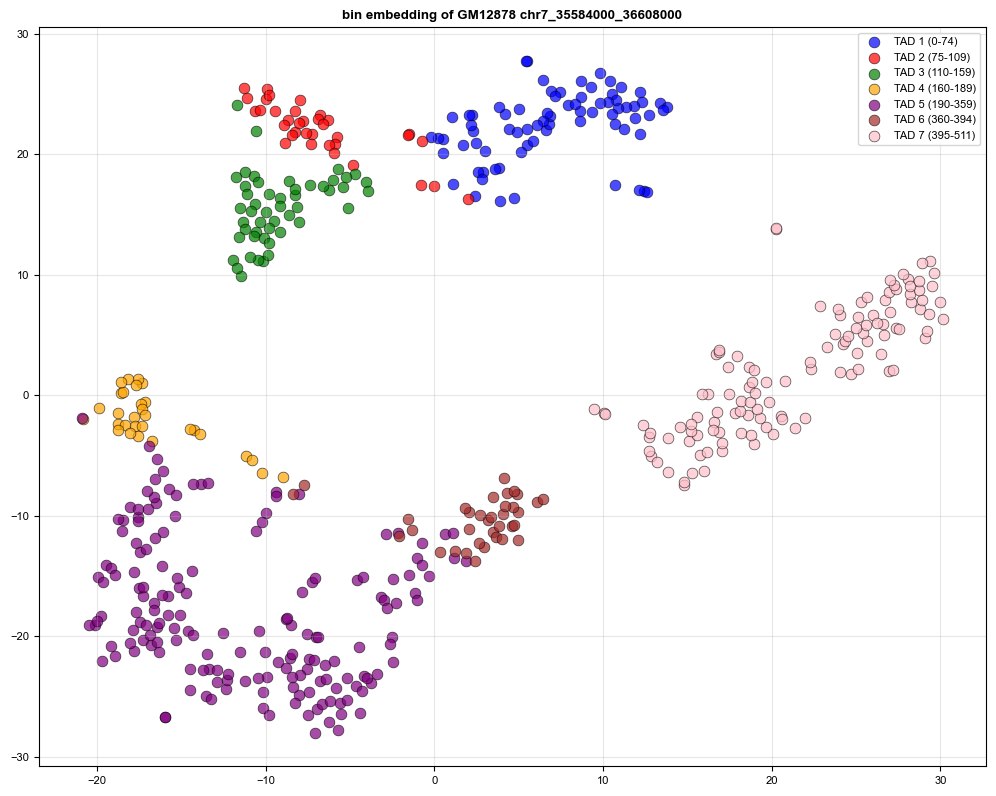

In [ ]:
seq_bc, omics_bc, hic_real = load_sample(BC_SAMPLE)

with torch.no_grad():
    fused = model.encode_fused(seq_bc.unsqueeze(0).to(device),
                               omics_bc.unsqueeze(0).to(device))
fused_np = fused.squeeze(0).cpu().numpy().T          # (512, 128)

emb_2d = TSNE(n_components=2, perplexity=30, learning_rate="auto",
              init="pca", random_state=42).fit_transform(fused_np)
emb_2d = (emb_2d - emb_2d.mean(0)) @ ALIGN.T

fig, ax = plt.subplots(figsize=(10, 8))
for i in range(len(TAD_BOUNDARIES) - 1):
    s, e = TAD_BOUNDARIES[i], TAD_BOUNDARIES[i + 1]
    ax.scatter(emb_2d[s:e, 0], emb_2d[s:e, 1], alpha=0.7, s=60,
               color=TAD_COLORS[i % len(TAD_COLORS)],
               label=f"TAD {i+1} ({s}-{e-1})", edgecolors="black", linewidth=0.5)
ax.grid(True, alpha=0.3)
ax.set_title("bin embedding of GM12878 chr7_35584000_36608000", fontweight="bold")
ax.legend()
fig.tight_layout()
save_fig(fig, "fig4_b", dpi=DPI_BC)
plt.show()


## 4. Panel d: prediction before editing

Window: chr7:45,824,000-46,848,000. The blue circle marks contact (264, 49), spanning 430 kb.


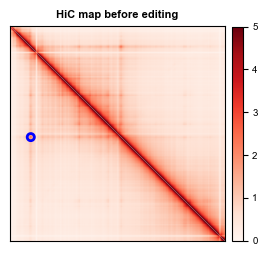

contact (264,49) before = 2.6487


In [ ]:
seq_edit, omics_edit0, _ = load_sample(EDIT_SAMPLE)
seq_b = seq_edit.unsqueeze(0).to(device)
omics_b = omics_edit0.unsqueeze(0).to(device)

with torch.no_grad():
    pred_before = model(seq_b, omics_b).squeeze(0).cpu().numpy()

fig, ax = plt.subplots(figsize=(3.0, 3.0))
heat_panel(ax, pred_before, "HiC map before editing")
save_fig(fig, "fig4_d", dpi=DPI_DGH, tight=True)
plt.show()
print(f"contact ({TARGET_I},{TARGET_J}) before = {pred_before[TARGET_I, TARGET_J]:.4f}")


## 5. Panel g: prediction after CTCF editing

Set CTCF channel 0 at bins 260-270 to z0 = -0.1724, the normalized value corresponding to zero raw signal.


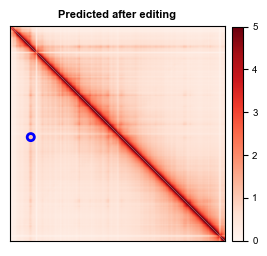

loop contact (264,49): 2.6487 -> 1.2371 (-53.3%)


In [6]:
omics_edit = omics_b.clone()
omics_edit[:, 0, EDIT_START:EDIT_END] = Z0_CTCF

with torch.no_grad():
    pred_after = model(seq_b, omics_edit).squeeze(0).cpu().numpy()

fig, ax = plt.subplots(figsize=(3.0, 3.0))
heat_panel(ax, pred_after, "Predicted after editing")
save_fig(fig, "fig4_g", dpi=DPI_DGH, tight=True)
plt.show()
l0 = float(pred_before[TARGET_I, TARGET_J])
l1 = float(pred_after[TARGET_I, TARGET_J])
print(f"loop contact ({TARGET_I},{TARGET_J}): {l0:.4f} -> {l1:.4f} ({100*(l1-l0)/l0:+.1f}%)")


## 6. Panel h: prediction after editing minus prediction before editing


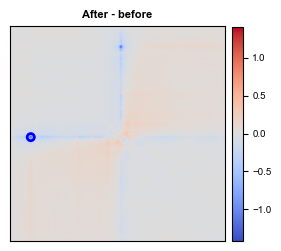

In [7]:
diff = pred_after - pred_before
lim = float(np.abs(diff).max())

fig, ax = plt.subplots(figsize=(3.0, 3.0))
heat_panel(ax, diff, "After - before", cmap="coolwarm", vmin=-lim, vmax=lim)
save_fig(fig, "fig4_h", dpi=DPI_DGH, tight=True)
plt.show()
print(f"diff: min={diff.min():+.3f} max={diff.max():+.3f}  max|diff|={lim:.3f}")
